In [2]:
# -------------------------------------------------------------------------
# Step 1: Imports, Config & Data Ingestion
# -------------------------------------------------------------------------
import os
import glob
import math
import time
import copy
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')
 
SMOKE = os.environ.get("CYBERSHIELD_SMOKE") == "1"   # tiny dry-run (no dataset needed)
if SMOKE:
    os.environ["HF_HUB_OFFLINE"] = "1"
 
SEED = 42
np.random.seed(SEED)
rng = np.random.RandomState(SEED)
 
IMG        = 64                       # heatmap is IMG x IMG
WIN        = IMG                      # flows per heatmap window
N_TRAIN    = 24  if SMOKE else 400    # training heatmaps per class
N_TEST     = 8   if SMOKE else 100    # real held-out heatmaps per class
GEN_PER_CL = 4   if SMOKE else 40     # generated heatmaps per class for evaluation
MIN_FLOWS  = 20                       # classes with fewer flows are dropped
T_STEPS    = 20  if SMOKE else 500    # diffusion steps
EPOCHS     = 2   if SMOKE else 80
BATCH      = 16  if SMOKE else 64
GUIDANCE   = 3.0                      # classifier-free guidance scale
OUT_DIR    = "." if SMOKE else "/kaggle/working"
 
if SMOKE:
    print("🧪 SMOKE MODE: synthetic data, tiny config")
    parts = []
    for k, name in enumerate(['BENIGN', 'DDoS', 'PortScan']):
        X = rng.randn(300, 70) * (1 + 0.3 * k) + k * np.linspace(-1, 1, 70) * 2
        d = pd.DataFrame(np.abs(X), columns=[f'f{i}' for i in range(70)])
        d['Label'] = name
        parts.append(d)
    df = pd.concat(parts, ignore_index=True)
else:
    DATASET_DIR = "/kaggle/input/datasets/chethuhn/network-intrusion-dataset"
    csv_files   = glob.glob(os.path.join(DATASET_DIR, "*.csv"))
    print(f"📁 Found {len(csv_files)} CSV file(s).")
    df_list = []
    for file_path in csv_files:
        print(f"   Reading: {os.path.basename(file_path)}...")
        sub_df = pd.read_csv(file_path, low_memory=False)
        if len(sub_df) > 40000:
            sub_df = sub_df.sample(n=40000, random_state=SEED)
        df_list.append(sub_df)
    df = pd.concat(df_list, axis=0, ignore_index=True)
 
df.columns = df.columns.str.strip()
target_col = "Label" if "Label" in df.columns else df.columns[-1]
 
cols_to_drop = [c for c in [
    "Flow ID", "Source IP", "Source Port", "Destination IP",
    "Destination Port", "Timestamp", "Unnamed: 0"
] if c in df.columns]
df = df.drop(columns=cols_to_drop)
df = df.replace([np.inf, -np.inf], np.nan).dropna()
df[target_col] = df[target_col].astype(str).str.strip()
 
# Keep BENIGN too: it is the "before attack" reference
counts      = df[target_col].value_counts()
valid       = sorted([c for c, n in counts.items() if n >= MIN_FLOWS])
df          = df[df[target_col].isin(valid)].reset_index(drop=True)
class_names = valid
K           = len(class_names)
class_to_id = {c: i for i, c in enumerate(class_names)}
 
feature_cols = df.drop(columns=[target_col]).select_dtypes(include=[np.number]).columns.tolist()
X_all = df[feature_cols].values.astype(np.float32)
y_all = df[target_col].map(class_to_id).values
 
print(f"\n📊 Dataset Summary:")
print(f"   Total rows : {len(df):,}   Features : {len(feature_cols)}   Classes : {K}")
for c in class_names:
    print(f"   {c:<40} {int((y_all == class_to_id[c]).sum()):>8,} flows")
 
print(f"\n✅ Step 1 Execution Completed.")

📁 Found 8 CSV file(s).
   Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...
   Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv...
   Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv...
   Reading: Monday-WorkingHours.pcap_ISCX.csv...
   Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...
   Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...
   Reading: Tuesday-WorkingHours.pcap_ISCX.csv...
   Reading: Wednesday-workingHours.pcap_ISCX.csv...

📊 Dataset Summary:
   Total rows : 319,716   Features : 77   Classes : 12
   BENIGN                                    258,121 flows
   Bot                                           382 flows
   DDoS                                       22,808 flows
   DoS GoldenEye                                 565 flows
   DoS Hulk                                   13,203 flows
   DoS Slowhttptest                              329 flows
   DoS slowloris                                 327 flows
   F

In [3]:
# -------------------------------------------------------------------------
# Step 2: Build Traffic Heatmap Images
# -------------------------------------------------------------------------
from sklearn.feature_selection import f_classif
 
# 2a. Robust per-feature scaling to [-1, 1] (1st–99th percentile)
lo = np.percentile(X_all, 1,  axis=0)
hi = np.percentile(X_all, 99, axis=0)
X_img = np.clip((X_all - lo) / (hi - lo + 1e-9), 0, 1) * 2 - 1
X_img = X_img.astype(np.float32)
 
# 2b. Pick the 64 most class-discriminative features (ANOVA F-score)
sub = rng.choice(len(X_img), size=min(50000, len(X_img)), replace=False)
F, _ = f_classif(X_img[sub], y_all[sub])
F = np.nan_to_num(F)
feat_idx = np.argsort(-F)[:IMG]
X_sel = X_img[:, feat_idx]
if X_sel.shape[1] < IMG:                       # pad if dataset has < 64 features
    pad = np.full((X_sel.shape[0], IMG - X_sel.shape[1]), -1.0, dtype=np.float32)
    X_sel = np.hstack([X_sel, pad])
sel_names = [feature_cols[i] for i in feat_idx]
 
# 2c. Split FLOWS per class (80/20) so test heatmaps use unseen flows
train_flows, test_flows = {}, {}
for c in range(K):
    flows = X_sel[y_all == c]
    flows = flows[rng.permutation(len(flows))]
    cut   = max(int(0.8 * len(flows)), 1)
    train_flows[c], test_flows[c] = flows[:cut], flows[cut:] if len(flows) - cut >= 5 else flows[:cut]
 
 
def make_windows(flow_dict, n_per_class):
    """Sample WIN flows, sort rows by the strongest feature (smooth image)."""
    imgs, labs = [], []
    for c, flows in flow_dict.items():
        for _ in range(n_per_class):
            idx = rng.choice(len(flows), WIN, replace=len(flows) < WIN)
            w   = flows[idx]
            imgs.append(w[np.argsort(w[:, 0])])
            labs.append(c)
    return np.stack(imgs)[:, None].astype(np.float32), np.array(labs)
 
 
X_train_img, y_train_img = make_windows(train_flows, N_TRAIN)
X_test_img,  y_test_img  = make_windows(test_flows,  N_TEST)
 
print(f"\n✅ Step 2 Execution Completed:")
print(f"   Train heatmaps : {X_train_img.shape}   Test heatmaps : {X_test_img.shape}")
print(f"   Columns (top features): {sel_names[:5]} ...")


✅ Step 2 Execution Completed:
   Train heatmaps : (4800, 1, 64, 64)   Test heatmaps : (1200, 1, 64, 64)
   Columns (top features): ['Bwd Packet Length Std', 'Bwd Packet Length Mean', 'Avg Bwd Segment Size', 'Bwd Packet Length Max', 'Packet Length Variance'] ...


In [4]:
# -------------------------------------------------------------------------
# Step 3: Text Encoder (CLIP) + Prompt Bank
# -------------------------------------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as Fn
from torch.utils.data import TensorDataset, DataLoader
 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"⚡ Device: {device}")
 
HAS_CLIP = False
try:
    from transformers import CLIPModel, CLIPProcessor
    clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
    clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    HAS_CLIP = True
    print("   ✅ CLIP text encoder loaded")
except Exception as e:
    print(f"   ⚠️  CLIP unavailable ({type(e).__name__}) → hashed bag-of-words text encoder")
    from sklearn.feature_extraction.text import HashingVectorizer
    hasher = HashingVectorizer(n_features=512, ngram_range=(1, 2),
                               alternate_sign=False, norm='l2')
 
TXT_DIM = 512
 
 
def _tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output
 
 
@torch.no_grad()
def encode_text(prompts):
    """list[str] -> (N, 512) L2-normalised embeddings."""
    if HAS_CLIP:
        inp = clip_proc(text=list(prompts), return_tensors="pt",
                        padding=True, truncation=True).to(device)
        e = _tensor(clip_model.get_text_features(**inp)).float()
    else:
        e = torch.tensor(hasher.transform(list(prompts)).toarray(), dtype=torch.float32)
    return Fn.normalize(e, dim=-1).to(device)
 
 
# Natural-language descriptions per attack family (3 paraphrases each)
DESC = [
    ('benign',      ["normal benign network traffic with regular user activity",
                     "baseline harmless traffic before any attack",
                     "healthy normal traffic with no malicious behaviour"]),
    ('ddos',        ["DDoS attack flooding port 80 from multiple IPs",
                     "distributed denial of service flood with huge packet rate from many sources",
                     "DDoS traffic overwhelming the web server from many hosts"]),
    ('portscan',    ["port scan probing many ports with tiny packets",
                     "reconnaissance scan sweeping through ports on the target",
                     "attacker scanning open ports across the network"]),
    ('patator',     ["brute force login attempts repeated against a service",
                     "password guessing attack with many failed logins",
                     "credential brute force with repeated short sessions"]),
    ('brute',       ["web brute force attack guessing passwords repeatedly",
                     "repeated login attempts against a web application",
                     "brute force password guessing on a web login"]),
    ('sql',         ["SQL injection attack sending malicious queries to a web app",
                     "web attack injecting SQL commands into requests",
                     "database injection attempt through web forms"]),
    ('xss',         ["cross site scripting attack injecting scripts into web pages",
                     "XSS web attack with malicious script payloads",
                     "web attack inserting client side scripts"]),
    ('bot',         ["botnet traffic with periodic command and control beacons",
                     "infected bot machines contacting the controller regularly",
                     "botnet activity with steady low volume callbacks"]),
    ('infiltration',["infiltration attack from inside the network moving laterally",
                     "stealthy infiltration with unusual internal connections",
                     "attacker inside the network exfiltrating data quietly"]),
    ('heartbleed',  ["heartbleed exploit leaking memory through long heartbeat sessions",
                     "heartbleed attack with large malformed heartbeat responses",
                     "TLS heartbeat exploit stealing server memory"]),
    ('dos',         ["denial of service attack exhausting the server from one source",
                     "DoS attack slowing the server with heavy requests",
                     "single source flood making the service unavailable"]),
    ('web attack',  ["web application attack with malicious HTTP requests",
                     "attack against a web server using crafted requests",
                     "malicious web traffic probing the application"]),
]
P = 4   # prompts per class (3 paraphrases + 1 generic)
 
 
def describe(cls_name):
    low = cls_name.lower()
    for key, prompts in DESC:
        if key in low:
            return prompts + [f"{cls_name} network traffic heatmap"]
    g = [f"{cls_name} attack traffic pattern", f"anomalous traffic of type {cls_name}",
         f"network flows from a {cls_name} attack"]
    return g + [f"{cls_name} network traffic heatmap"]
 
 
class_prompts = {c: describe(c) for c in class_names}
prompt_bank = torch.stack([encode_text(class_prompts[c]) for c in class_names])  # (K, P, 512)
 
print(f"\n✅ Step 3 Execution Completed:")
for c in class_names[:4]:
    print(f"   {c:<28} → \"{class_prompts[c][0]}\"")

⚡ Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

   ✅ CLIP text encoder loaded

✅ Step 3 Execution Completed:
   BENIGN                       → "normal benign network traffic with regular user activity"
   Bot                          → "botnet traffic with periodic command and control beacons"
   DDoS                         → "DDoS attack flooding port 80 from multiple IPs"
   DoS GoldenEye                → "denial of service attack exhausting the server from one source"


In [5]:
# -------------------------------------------------------------------------
# Step 4: Conditional U-Net + DDPM Schedule
# -------------------------------------------------------------------------
def sinusoidal(t, dim):
    half  = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], dim=1)
 
 
class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin);  self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.e  = nn.Linear(emb, cout)
        self.n2 = nn.GroupNorm(8, cout); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
 
    def forward(self, x, e):
        h = self.c1(Fn.silu(self.n1(x)))
        h = h + self.e(e)[:, :, None, None]
        h = self.c2(Fn.silu(self.n2(h)))
        return h + self.skip(x)
 
 
class SelfAttn(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n   = nn.GroupNorm(8, c)
        self.qkv = nn.Conv2d(c, 3 * c, 1)
        self.o   = nn.Conv2d(c, c, 1)
 
    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.n(x)).reshape(B, 3, C, H * W).unbind(1)   # (B, C, N)
        h = Fn.scaled_dot_product_attention(
            q.transpose(1, 2)[:, None], k.transpose(1, 2)[:, None], v.transpose(1, 2)[:, None]
        )[:, 0]                                                           # (B, N, C)
        return x + self.o(h.transpose(1, 2).reshape(B, C, H, W))
 
 
class CondUNet(nn.Module):
    """
    U-Net that predicts the noise in a heatmap.
    Conditioned on diffusion timestep + CLIP text embedding (added into every block).
    64x64 → 32x32 → 16x16 (attention) → back up with skip connections.
    """
    def __init__(self, txt_dim=TXT_DIM, base=64, emb=256):
        super().__init__()
        self.emb   = emb
        self.t_mlp = nn.Sequential(nn.Linear(emb, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.c_mlp = nn.Sequential(nn.Linear(txt_dim, emb), nn.SiLU(), nn.Linear(emb, emb))
 
        self.inc   = nn.Conv2d(1, base, 3, padding=1)
        self.d1    = ResBlock(base, base, emb)
        self.down1 = nn.Conv2d(base, base * 2, 3, stride=2, padding=1)
        self.d2    = ResBlock(base * 2, base * 2, emb)
        self.down2 = nn.Conv2d(base * 2, base * 4, 3, stride=2, padding=1)
        self.d3    = ResBlock(base * 4, base * 4, emb)
        self.a3    = SelfAttn(base * 4)
 
        self.mid1  = ResBlock(base * 4, base * 4, emb)
        self.mida  = SelfAttn(base * 4)
        self.mid2  = ResBlock(base * 4, base * 4, emb)
 
        self.u3  = ResBlock(base * 8, base * 4, emb)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1)
        self.u2  = ResBlock(base * 4, base * 2, emb)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.u1  = ResBlock(base * 2, base, emb)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(),
                                 nn.Conv2d(base, 1, 3, padding=1))
 
    def forward(self, x, t, c):
        e  = self.t_mlp(sinusoidal(t, self.emb)) + self.c_mlp(c)
        h0 = self.d1(self.inc(x), e)                       # 64x64
        h1 = self.d2(self.down1(h0), e)                    # 32x32
        h2 = self.a3(self.d3(self.down2(h1), e))           # 16x16
        m  = self.mid2(self.mida(self.mid1(h2, e)), e)
        u  = self.u3(torch.cat([m, h2], 1), e)
        u  = self.u2(torch.cat([self.up2(u), h1], 1), e)
        u  = self.u1(torch.cat([self.up1(u), h0], 1), e)
        return self.out(u)
 
 
# DDPM noise schedule
betas  = torch.linspace(1e-4, 0.02 * 1000 / T_STEPS, T_STEPS, device=device)
alphas = 1.0 - betas
abar   = torch.cumprod(alphas, dim=0)
abar_prev = torch.cat([torch.ones(1, device=device), abar[:-1]])
post_c1   = betas * abar_prev.sqrt() / (1 - abar)
post_c2   = (1 - abar_prev) * alphas.sqrt() / (1 - abar)
post_var  = betas * (1 - abar_prev) / (1 - abar)
 
model = CondUNet().to(device)
ema   = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)
 
print(f"\n✅ Step 4 Execution Completed:")
print(f"   U-Net params : {sum(p.numel() for p in model.parameters()):,}")
print(f"   Diffusion steps (T) : {T_STEPS}")


✅ Step 4 Execution Completed:
   U-Net params : 8,655,681
   Diffusion steps (T) : 500


In [6]:
# -------------------------------------------------------------------------
# Step 5: Training (with classifier-free guidance dropout + EMA)
# -------------------------------------------------------------------------
loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_train_img), torch.LongTensor(y_train_img)),
    batch_size=BATCH, shuffle=True, drop_last=True
)
opt     = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
sched   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
use_amp = device.type == "cuda"
scaler_amp = torch.cuda.amp.GradScaler(enabled=use_amp)
P_UNCOND, EMA_DECAY = 0.1, 0.995
 
diff_losses = []     # training MSE (noise prediction) per epoch
val_losses  = []     # validation MSE on held-out real heatmaps per epoch
val_maes    = []     # validation MAE (L1) per epoch, monitored alongside MSE
 
val_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_test_img), torch.LongTensor(y_test_img)),
    batch_size=BATCH, shuffle=False
)
 
 
@torch.no_grad()
def validate():
    """Same noise-prediction loss on unseen heatmaps. Fixed seed → comparable across epochs."""
    model.eval()
    g = torch.Generator(device=device).manual_seed(SEED)
    sum_mse, sum_mae, n = 0.0, 0.0, 0
    for x0, y in val_loader:
        x0, y = x0.to(device), y.to(device)
        B     = x0.size(0)
        c     = prompt_bank[y, torch.zeros(B, dtype=torch.long, device=device)]
        t     = torch.randint(0, T_STEPS, (B,), device=device, generator=g)
        noise = torch.randn(x0.shape, device=device, generator=g)
        ab    = abar[t][:, None, None, None]
        xt    = ab.sqrt() * x0 + (1 - ab).sqrt() * noise
        pred  = model(xt, t, c)
        sum_mse += Fn.mse_loss(pred, noise, reduction='sum').item()
        sum_mae += Fn.l1_loss(pred, noise, reduction='sum').item()
        n       += noise.numel()
    return sum_mse / n, sum_mae / n
 
 
print(f"\n🚀 Training diffusion model for {EPOCHS} epochs on {device.type.upper()}...")
start = time.time()
 
for epoch in range(1, EPOCHS + 1):
    model.train()
    run, nb = 0.0, 0
    for x0, y in loader:
        x0, y = x0.to(device), y.to(device)
        B = x0.size(0)
 
        # random paraphrase of the class prompt; 10% blank prompt → unconditional
        c = prompt_bank[y, torch.randint(P, (B,), device=device)]
        c = torch.where((torch.rand(B, 1, device=device) < P_UNCOND), torch.zeros_like(c), c)
 
        t     = torch.randint(0, T_STEPS, (B,), device=device)
        noise = torch.randn_like(x0)
        ab    = abar[t][:, None, None, None]
        xt    = ab.sqrt() * x0 + (1 - ab).sqrt() * noise
 
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss = Fn.mse_loss(model(xt, t, c), noise)
 
        opt.zero_grad(set_to_none=True)
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler_amp.step(opt)
        scaler_amp.update()
 
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(EMA_DECAY).add_(pm.detach(), alpha=1 - EMA_DECAY)
 
        run += loss.item(); nb += 1
    sched.step()
    diff_losses.append(run / max(nb, 1))
    v_mse, v_mae = validate()
    val_losses.append(v_mse)
    val_maes.append(v_mae)
 
    if epoch % 10 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"Epoch [{epoch:03d}/{EPOCHS}] | Train MSE: {diff_losses[-1]:.5f} | "
              f"Val MSE: {v_mse:.5f} | Val MAE: {v_mae:.5f} | "
              f"Time: {(time.time() - start) / 60:.1f}m")
 
print(f"\n✅ Step 5 Execution Completed: trained in {(time.time() - start) / 60:.2f} min.")


🚀 Training diffusion model for 80 epochs on CUDA...
Epoch [001/80] | Train MSE: 0.17228 | Val MSE: 0.08127 | Val MAE: 0.15681 | Time: 0.3m
Epoch [010/80] | Train MSE: 0.02797 | Val MSE: 0.02803 | Val MAE: 0.07149 | Time: 2.7m
Epoch [020/80] | Train MSE: 0.02093 | Val MSE: 0.02139 | Val MAE: 0.05849 | Time: 5.5m
Epoch [030/80] | Train MSE: 0.01857 | Val MSE: 0.01892 | Val MAE: 0.05296 | Time: 8.2m
Epoch [040/80] | Train MSE: 0.01602 | Val MSE: 0.01736 | Val MAE: 0.05141 | Time: 10.9m
Epoch [050/80] | Train MSE: 0.01478 | Val MSE: 0.01538 | Val MAE: 0.04437 | Time: 13.7m
Epoch [060/80] | Train MSE: 0.01305 | Val MSE: 0.01428 | Val MAE: 0.04142 | Time: 16.4m
Epoch [070/80] | Train MSE: 0.01253 | Val MSE: 0.01375 | Val MAE: 0.03994 | Time: 19.1m
Epoch [080/80] | Train MSE: 0.01195 | Val MSE: 0.01361 | Val MAE: 0.03961 | Time: 21.9m

✅ Step 5 Execution Completed: trained in 21.88 min.


In [7]:
# -------------------------------------------------------------------------
# Step 6: Sampling — Text Prompt → Heatmap
# -------------------------------------------------------------------------
@torch.no_grad()
def sample_heatmaps(cond, scale=GUIDANCE, net=None):
    """Reverse diffusion with classifier-free guidance. cond: (B, 512)."""
    net = net or ema
    B   = cond.size(0)
    x   = torch.randn(B, 1, IMG, IMG, device=device)
    c2  = torch.cat([cond, torch.zeros_like(cond)], 0)
    for i in reversed(range(T_STEPS)):
        t   = torch.full((2 * B,), i, device=device, dtype=torch.long)
        eps = net(torch.cat([x, x], 0), t, c2)
        e_c, e_u = eps[:B], eps[B:]
        eps = e_u + scale * (e_c - e_u)
        x0  = ((x - (1 - abar[i]).sqrt() * eps) / abar[i].sqrt()).clamp(-1, 1)
        mean = post_c1[i] * x0 + post_c2[i] * x
        x = mean + post_var[i].sqrt() * torch.randn_like(x) if i > 0 else mean
    return x.clamp(-1, 1).cpu().numpy()
 
 
def text_to_heatmap(prompt, n=4, scale=GUIDANCE):
    """Public API: any English description → n heatmaps (n,1,64,64) in [-1,1]."""
    cond = encode_text([prompt]).repeat(n, 1)
    return sample_heatmaps(cond, scale)
 
 
print(f"\n🔧 Generating {GEN_PER_CL} heatmaps per class...")
gen_imgs = {}
for ci, cname in enumerate(class_names):
    cond = prompt_bank[ci, 0].unsqueeze(0).repeat(GEN_PER_CL, 1)
    gen_imgs[ci] = sample_heatmaps(cond)
    print(f"   {cname:<36} done")
 
X_gen = np.concatenate([gen_imgs[c] for c in range(K)])
y_gen = np.repeat(np.arange(K), GEN_PER_CL)
 
print(f"\n✅ Step 6 Execution Completed: {X_gen.shape[0]} generated heatmaps.")


🔧 Generating 40 heatmaps per class...
   BENIGN                               done
   Bot                                  done
   DDoS                                 done
   DoS GoldenEye                        done
   DoS Hulk                             done
   DoS Slowhttptest                     done
   DoS slowloris                        done
   FTP-Patator                          done
   PortScan                             done
   SSH-Patator                          done
   Web Attack � Brute Force             done
   Web Attack � XSS                     done

✅ Step 6 Execution Completed: 480 generated heatmaps.


In [8]:
# -------------------------------------------------------------------------
# Step 7: Evaluation — SSIM, FID, CLIP Score, Class Accuracy
# -------------------------------------------------------------------------
from scipy import linalg
from skimage.metrics import structural_similarity as ssim_fn
import matplotlib
import matplotlib.pyplot as plt
 
print("\n📊 Evaluating...")
 
# ── 7a. SSIM vs class-average real heatmap (real-test row = upper reference)
class_mean_real = {c: X_train_img[y_train_img == c].mean(0)[0] for c in range(K)}
ssim_gen  = np.mean([ssim_fn(X_gen[i, 0],      class_mean_real[y_gen[i]],      data_range=2.0)
                     for i in range(len(X_gen))])
ssim_real = np.mean([ssim_fn(X_test_img[i, 0], class_mean_real[y_test_img[i]], data_range=2.0)
                     for i in range(len(X_test_img))])
 
# ── 7a-2. PSNR (dB) vs class-average real heatmap, same reference as SSIM
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
psnr_gen  = np.mean([psnr_fn(class_mean_real[y_gen[i]], X_gen[i, 0], data_range=2.0)
                     for i in range(len(X_gen))])
psnr_real = np.mean([psnr_fn(class_mean_real[y_test_img[i]], X_test_img[i, 0], data_range=2.0)
                     for i in range(len(X_test_img))])
 
# ── 7b. FID (Inception features; falls back to pixel-PCA "FID-lite")
def inception_feats():
    try:
        import torchvision
        m = torchvision.models.inception_v3(
            weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)
        m.fc = nn.Identity()
        return m.to(device).eval()
    except Exception:
        return None
 
incep = inception_feats()
FID_NAME = "FID" if incep is not None else "FID-lite (pixel PCA)"
if incep is None:
    from sklearn.decomposition import PCA
    pca_fid = PCA(n_components=min(64, len(X_test_img) - 1, IMG * IMG)).fit(X_test_img.reshape(len(X_test_img), -1))
 
@torch.no_grad()
def feats(imgs):
    if incep is None:
        return pca_fid.transform(imgs.reshape(len(imgs), -1))
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(imgs), 50):
        x = torch.FloatTensor(imgs[i:i + 50]).to(device)
        x = ((x + 1) / 2).repeat(1, 3, 1, 1)
        x = Fn.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False)
        out.append(incep((x - mean) / std).cpu().numpy())
    return np.concatenate(out)
 
def fid_score(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1 = np.cov(a, rowvar=False) + 1e-6 * np.eye(a.shape[1])
    s2 = np.cov(b, rowvar=False) + 1e-6 * np.eye(b.shape[1])
    cov = linalg.sqrtm(s1.dot(s2))
    if np.iscomplexobj(cov):
        cov = cov.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(cov))
 
fid_val = fid_score(feats(X_test_img), feats(X_gen))
 
# ── 7c. CLIP score (heatmap rendered with a colormap vs its prompt)
clip_match, clip_mismatch = float('nan'), float('nan')
if HAS_CLIP:
    from PIL import Image
    cmap = matplotlib.colormaps['inferno']
    def to_pil(a):
        return Image.fromarray((cmap((a[0] + 1) / 2)[..., :3] * 255).astype(np.uint8))
    sel = np.arange(0, len(X_gen), max(1, len(X_gen) // 100))
    with torch.no_grad():
        inp = clip_proc(images=[to_pil(X_gen[i]) for i in sel], return_tensors="pt").to(device)
        img_e = Fn.normalize(_tensor(clip_model.get_image_features(**inp)).float(), dim=-1)
    txt_match = prompt_bank[torch.as_tensor(y_gen[sel], device=device), 0]
    txt_other = prompt_bank[torch.as_tensor((y_gen[sel] + 1) % K, device=device), 0]
    clip_match    = float(100 * (img_e * txt_match).sum(-1).mean())
    clip_mismatch = float(100 * (img_e * txt_other).sum(-1).mean())
 
# ── 7d. Conditional accuracy: does a classifier trained on REAL heatmaps
#        recognise the class the prompt asked for?
class HeatmapCNN(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 3, 2, 1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, k))
    def forward(self, x):
        return self.net(x)
 
clf = HeatmapCNN(K).to(device)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
clf_loader = DataLoader(TensorDataset(torch.FloatTensor(X_train_img), torch.LongTensor(y_train_img)),
                        batch_size=64, shuffle=True)
for _ in range(2 if SMOKE else 15):
    for xb, yb in clf_loader:
        loss = Fn.cross_entropy(clf(xb.to(device)), yb.to(device))
        clf_opt.zero_grad(); loss.backward(); clf_opt.step()
 
@torch.no_grad()
def predict(imgs):
    clf.eval()
    return clf(torch.FloatTensor(imgs).to(device)).argmax(1).cpu().numpy()
 
acc_real = float((predict(X_test_img) == y_test_img).mean())
pred_gen = predict(X_gen)
acc_gen  = float((pred_gen == y_gen).mean())
per_class_acc = [float((pred_gen[y_gen == c] == c).mean()) for c in range(K)]
 
df_cmp = pd.DataFrame({
    'Metric': ['Training MSE ↓ (final)', 'Validation MSE ↓ (final)', 'Validation MAE/L1 ↓ (final)',
               f'{FID_NAME} ↓', 'SSIM ↑ (vs class-avg real)', 'PSNR ↑ dB (vs class-avg real)',
               'CLIP Score ↑ (matched prompt)', 'CLIP Score (mismatched prompt)',
               'Class accuracy ↑ (generated)', 'Class accuracy (real test, ceiling)'],
    'Diffusion': [round(diff_losses[-1], 5), round(val_losses[-1], 5), round(val_maes[-1], 5),
                  round(fid_val, 2), round(float(ssim_gen), 4), round(float(psnr_gen), 2),
                  round(clip_match, 2), round(clip_mismatch, 2), round(acc_gen, 4), round(acc_real, 4)],
    'Real test': ['-', '-', '-', 0.0, round(float(ssim_real), 4), round(float(psnr_real), 2),
                  '-', '-', '-', round(acc_real, 4)],
})
 
print(f"\n{'=' * 70}\n  DIFFUSION QUALITY\n{'=' * 70}")
print(df_cmp.to_string(index=False))
print(f"\n✅ Step 7 Execution Completed.")


📊 Evaluating...
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 216MB/s]  



  DIFFUSION QUALITY
                             Metric  Diffusion Real test
             Training MSE ↓ (final)    0.01195         -
           Validation MSE ↓ (final)    0.01361         -
        Validation MAE/L1 ↓ (final)    0.03961         -
                              FID ↓   36.85000       0.0
         SSIM ↑ (vs class-avg real)    0.52940     0.714
      PSNR ↑ dB (vs class-avg real)   16.12000     18.66
      CLIP Score ↑ (matched prompt)   23.88000         -
     CLIP Score (mismatched prompt)   23.93000         -
       Class accuracy ↑ (generated)    0.41460         -
Class accuracy (real test, ceiling)    0.95250    0.9525

✅ Step 7 Execution Completed.


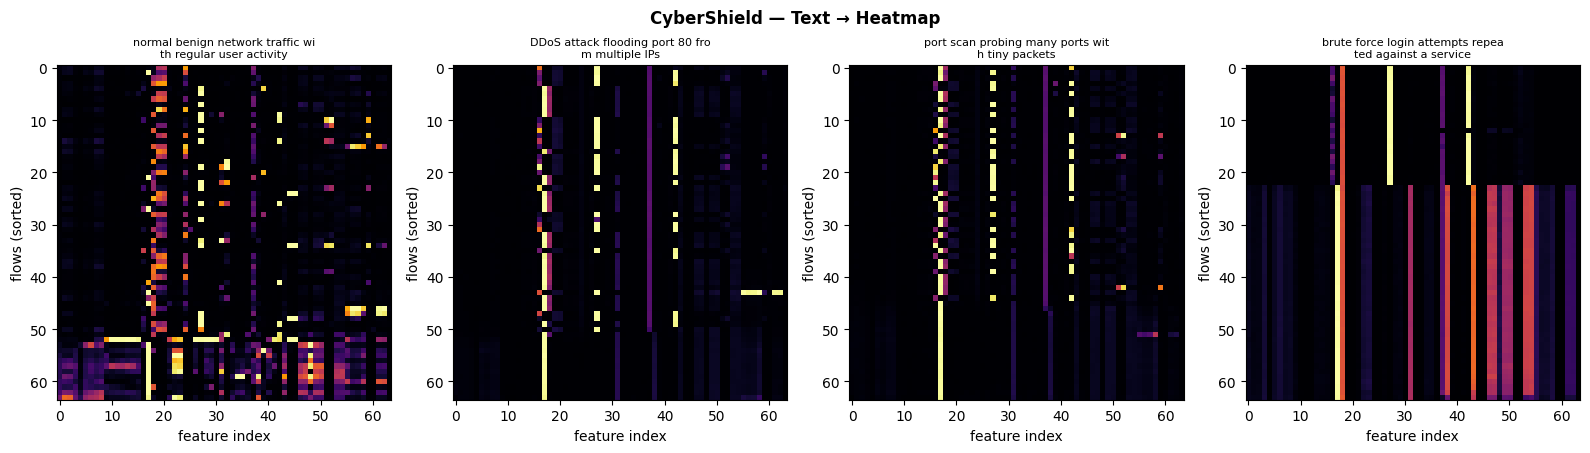


✅ Step 8 Execution Completed.


In [10]:
# -------------------------------------------------------------------------
# Step 8: Before-Attack vs During-Attack + Custom Text Prompts
# -------------------------------------------------------------------------
benign_id = next((i for i, c in enumerate(class_names) if c.upper() == 'BENIGN'), 0)
atk_id    = next((i for i, c in enumerate(class_names)
                  if 'ddos' in c.lower()), next(i for i in range(K) if i != benign_id))
 
mean_benign = gen_imgs[benign_id].mean(0)[0]
mean_attack = gen_imgs[atk_id].mean(0)[0]
diff_map    = mean_attack - mean_benign
 
CUSTOM_PROMPTS = [
    "normal benign network traffic with regular user activity",
    "DDoS attack flooding port 80 from multiple IPs",
    "port scan probing many ports with tiny packets",
    "brute force login attempts repeated against a service",
]
custom = {p: text_to_heatmap(p, n=1)[0, 0] for p in CUSTOM_PROMPTS}
 
fig, axes = plt.subplots(1, len(CUSTOM_PROMPTS), figsize=(4 * len(CUSTOM_PROMPTS), 4.4))
for ax, (p, im) in zip(np.atleast_1d(axes), custom.items()):
    ax.imshow(im, cmap='inferno', vmin=-1, vmax=1)
    ax.set_title("\n".join([p[i:i + 32] for i in range(0, len(p), 32)]), fontsize=8)
    ax.set_xlabel("feature index"); ax.set_ylabel("flows (sorted)")
plt.suptitle("CyberShield — Text → Heatmap", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'text_to_heatmap_demo.png'), dpi=150, bbox_inches='tight')
plt.show()
 
print(f"\n✅ Step 8 Execution Completed.")


📊 Generating diffusion dashboard...


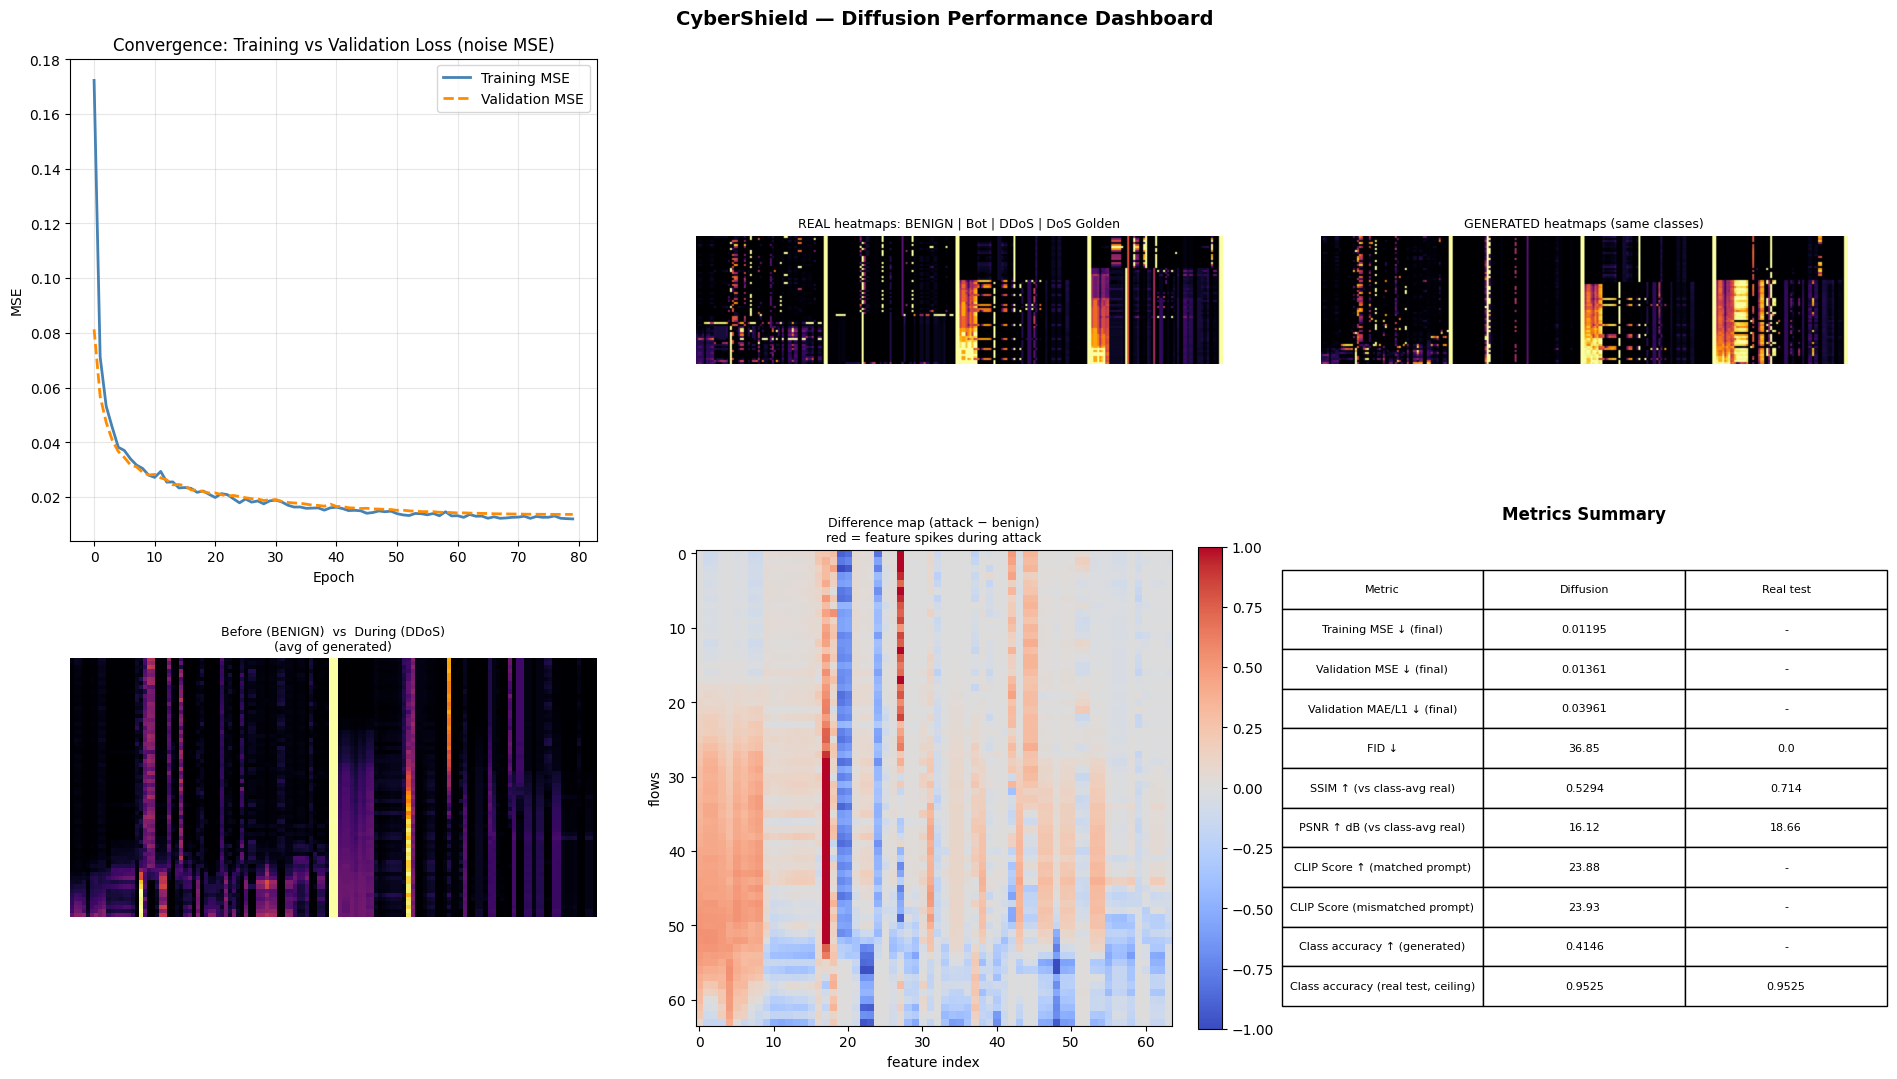

   Saved → diffusion_dashboard.png

✅ Step 9 Execution Completed.


In [11]:
# -------------------------------------------------------------------------
# Step 9: Visualization Dashboard
# -------------------------------------------------------------------------
print("\n📊 Generating diffusion dashboard...")
 
def montage(imgs):
    return np.hstack([np.pad(i, ((0, 0), (0, 2)), constant_values=1) for i in imgs])
 
show = list(range(min(4, K)))
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
fig.suptitle('CyberShield — Diffusion Performance Dashboard', fontsize=14, fontweight='bold')
 
axes[0, 0].plot(diff_losses, color='steelblue', linewidth=2, label='Training MSE')
axes[0, 0].plot(val_losses,  color='darkorange', linewidth=2, linestyle='--', label='Validation MSE')
axes[0, 0].set_title('Convergence: Training vs Validation Loss (noise MSE)')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('MSE')
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)
 
axes[0, 1].imshow(montage([X_test_img[y_test_img == c][0, 0] for c in show]),
                  cmap='inferno', vmin=-1, vmax=1)
axes[0, 1].set_title('REAL heatmaps: ' + ' | '.join(class_names[c][:10] for c in show), fontsize=9)
axes[0, 1].axis('off')
 
axes[0, 2].imshow(montage([gen_imgs[c][0, 0] for c in show]), cmap='inferno', vmin=-1, vmax=1)
axes[0, 2].set_title('GENERATED heatmaps (same classes)', fontsize=9)
axes[0, 2].axis('off')
 
pair = np.hstack([mean_benign, np.ones((IMG, 2)), mean_attack])
axes[1, 0].imshow(pair, cmap='inferno', vmin=-1, vmax=1)
axes[1, 0].set_title(f'Before (BENIGN)  vs  During ({class_names[atk_id][:14]})\n(avg of generated)',
                     fontsize=9)
axes[1, 0].axis('off')
 
im = axes[1, 1].imshow(diff_map, cmap='coolwarm', vmin=-1, vmax=1)
axes[1, 1].set_title('Difference map (attack − benign)\nred = feature spikes during attack', fontsize=9)
axes[1, 1].set_xlabel('feature index'); axes[1, 1].set_ylabel('flows')
plt.colorbar(im, ax=axes[1, 1], fraction=0.046)
 
axes[1, 2].axis('off')
tbl = axes[1, 2].table(cellText=df_cmp.values, colLabels=df_cmp.columns,
                       loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1.15, 1.9)
axes[1, 2].set_title('Metrics Summary', fontweight='bold', pad=20)
 
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'diffusion_dashboard.png'), dpi=150, bbox_inches='tight')
plt.show()
print("   Saved → diffusion_dashboard.png")
 
print(f"\n✅ Step 9 Execution Completed.")

In [12]:
# -------------------------------------------------------------------------
# Step 10: Save Model & Outputs
# -------------------------------------------------------------------------
import joblib
 
torch.save({
    'ema_state_dict'   : ema.state_dict(),
    'model_state_dict' : model.state_dict(),
    'class_names'      : class_names,
    'feature_idx'      : feat_idx,
    'feature_names'    : sel_names,
    'lo': lo, 'hi': hi,
    'img_size': IMG, 'T': T_STEPS, 'guidance': GUIDANCE,
    'losses': diff_losses, 'val_losses': val_losses, 'val_maes': val_maes,
}, os.path.join(OUT_DIR, 'cybershield_diffusion.pth'))
 
pd.DataFrame({'epoch': np.arange(1, len(diff_losses) + 1), 'train_mse': diff_losses,
              'val_mse': val_losses, 'val_mae_l1': val_maes}
             ).to_csv(os.path.join(OUT_DIR, 'diffusion_loss_history.csv'), index=False)
 
np.save(os.path.join(OUT_DIR, 'diffusion_generated_heatmaps.npy'), X_gen)
np.save(os.path.join(OUT_DIR, 'diffusion_generated_labels.npy'), y_gen)
df_cmp.to_csv(os.path.join(OUT_DIR, 'diffusion_comparison.csv'), index=False)
joblib.dump(class_names, os.path.join(OUT_DIR, 'diffusion_class_names.pkl'))
 
print("\n💾 Saved:")
print("   cybershield_diffusion.pth          ← U-Net weights (EMA + raw) + config")
print("   diffusion_generated_heatmaps.npy   ← generated heatmaps")
print("   diffusion_comparison.csv           ← metrics table")
print("   diffusion_loss_history.csv         ← train/val loss per epoch")
print("   text_to_heatmap_demo.png           ← prompt → heatmap demo")
print("   diffusion_dashboard.png            ← visualization dashboard")
 
print(f"\n{'=' * 60}\n  ✅ Diffusion Module Complete\n{'=' * 60}")
print(f"  Train MSE (final): {diff_losses[-1]:.5f}")
print(f"  Val MSE (final)  : {val_losses[-1]:.5f}   Val MAE/L1: {val_maes[-1]:.5f}")
print(f"  SSIM             : {ssim_gen:.4f}  (real-test ref {ssim_real:.4f})")
print(f"  PSNR             : {psnr_gen:.2f} dB  (real-test ref {psnr_real:.2f} dB)")
print(f"  {FID_NAME:<17}: {fid_val:.2f}  (lower = better)")
print(f"  CLIP score       : {clip_match:.2f}")
print(f"  Class accuracy   : {acc_gen:.2%}  (real ceiling {acc_real:.2%})")


💾 Saved:
   cybershield_diffusion.pth          ← U-Net weights (EMA + raw) + config
   diffusion_generated_heatmaps.npy   ← generated heatmaps
   diffusion_comparison.csv           ← metrics table
   diffusion_loss_history.csv         ← train/val loss per epoch
   text_to_heatmap_demo.png           ← prompt → heatmap demo
   diffusion_dashboard.png            ← visualization dashboard

  ✅ Diffusion Module Complete
  Train MSE (final): 0.01195
  Val MSE (final)  : 0.01361   Val MAE/L1: 0.03961
  SSIM             : 0.5294  (real-test ref 0.7140)
  PSNR             : 16.12 dB  (real-test ref 18.66 dB)
  FID              : 36.85  (lower = better)
  CLIP score       : 23.88
  Class accuracy   : 41.46%  (real ceiling 95.25%)


In [13]:
# =========================================================================
# CyberShield — Diffusion Demo GUI (Gradio)
#
# HOW TO USE
#   Paste this as the LAST cell of your diffusion notebook, after Step 10,
#   and run it. It reuses the trained model and results already in memory.
#   Kaggle: turn Internet ON (Settings → Internet) so the public link works.
#   It prints a link like  https://xxxx.gradio.live  — open it to present.
# =========================================================================
import sys
import time
import subprocess

try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image


def to_rgb(a, cm='inferno', lo=-1.0, hi=1.0, size=384):
    """Heatmap array → coloured, enlarged picture."""
    a = np.clip(np.asarray(a, dtype=np.float32), lo, hi)
    rgb = matplotlib.colormaps[cm](((a - lo) / (hi - lo)))[..., :3]
    return Image.fromarray((rgb * 255).astype(np.uint8)).resize((size, size), Image.NEAREST)


EXAMPLES = [
    "normal benign network traffic with regular user activity",
    "DDoS attack flooding port 80 from multiple IPs",
    "port scan probing many ports with tiny packets",
    "brute force login attempts repeated against a service",
    "botnet traffic with periodic command and control beacons",
]

attack_choices = [c for i, c in enumerate(class_names) if i != benign_id]
default_attack = next((c for c in attack_choices if 'ddos' in c.lower()), attack_choices[0])


# ── Tab 1: live text → heatmap ───────────────────────────────────────────
def generate(prompt, n, scale):
    if not prompt or not prompt.strip():
        raise gr.Error("Type an attack description first.")
    imgs = text_to_heatmap(prompt, n=int(n), scale=float(scale))
    return [to_rgb(im[0]) for im in imgs]


# ── Tab 2: before vs during attack (uses images generated in Step 6) ─────
def compare(attack_name):
    a      = class_names.index(attack_name)
    benign = gen_imgs[benign_id].mean(0)[0]
    attack = gen_imgs[a].mean(0)[0]
    diff   = attack - benign
    return to_rgb(benign), to_rgb(attack), to_rgb(diff, cm='coolwarm')


# ── Tab 3: results ───────────────────────────────────────────────────────
fig_loss, ax = plt.subplots(figsize=(7, 4))
ax.plot(diff_losses, color='steelblue', linewidth=2, label='Training MSE')
ax.plot(val_losses, color='darkorange', linewidth=2, linestyle='--', label='Validation MSE')
ax.set_title('Convergence: training vs validation loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.legend()
ax.grid(True, alpha=0.3)
plt.close(fig_loss)

with gr.Blocks(title="CyberShield — Diffusion Demo", theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        "# 🛡️ CyberShield — Text-to-Heatmap\n"
        "Describe a network attack in words and the diffusion model draws its "
        "traffic heatmap. Bright = high feature value; each attack type has a "
        "different visual signature."
    )

    with gr.Tab("1 · Text → Heatmap"):
        with gr.Row():
            with gr.Column(scale=1):
                prompt = gr.Textbox(label="Attack description", value=EXAMPLES[1], lines=2)
                gr.Examples(examples=[[e] for e in EXAMPLES], inputs=prompt, label="Try an example")
                n_img = gr.Slider(1, 4, value=2, step=1, label="Number of heatmaps")
                scale = gr.Slider(1, 6, value=GUIDANCE, step=0.5, label="Guidance strength")
                btn = gr.Button("Generate heatmap", variant="primary")
            gallery = gr.Gallery(label="Generated heatmaps", columns=2, height=440)
        btn.click(generate, [prompt, n_img, scale], gallery)

    with gr.Tab("2 · Before vs During Attack"):
        gr.Markdown("Average generated heatmap for normal traffic, for an attack, and the difference. "
                    "In the difference map, red = values that rise during the attack and blue = values that fall.")
        attack_dd = gr.Dropdown(attack_choices, value=default_attack, label="Attack type")
        cmp_btn = gr.Button("Compare", variant="primary")
        with gr.Row():
            img_benign = gr.Image(label="Before: normal traffic", height=380)
            img_attack = gr.Image(label="During: attack traffic", height=380)
            img_diff = gr.Image(label="Difference (attack − normal)", height=380)
        cmp_btn.click(compare, attack_dd, [img_benign, img_attack, img_diff])

    with gr.Tab("3 · Results"):
        gr.Markdown("### Model quality metrics")
        gr.Dataframe(value=df_cmp, interactive=False)
        gr.Plot(value=fig_loss, label="Training vs validation loss")

demo.launch(share=True, debug=False)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://1c582004fd45529e9a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
